# Predictive Maintenance — Final Executed Notebook

Harshit Rathi

Companion to **Harshit_Rathi_PredictiveMaintenance_FinalReport.pdf**. This notebook contains the full analytical code, all tuning results, the committed-model evaluation, the Streamlit source, workflow source and captured deployment evidence.

Run from the repository root after installing requirements.txt. All EDA uses training observations. The held-out data are never used to select model parameters or a threshold.

### Dataset source and interpretation

Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023). The user-supplied engine_data.csv was verified byte-for-byte against the public download on 2 November 2026. Collection protocol and pressure/temperature units remain unverified.

The healthy/faulty mapping remains unverified because external sources conflict. This report retains class 0/class 1 terminology throughout. Class 1 is the positive class solely for statistical evaluation; it does not imply healthy, faulty, or better condition.

- [Original dataset: Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023)](https://www.kaggle.com/datasets/parvmodi/automotive-vehicles-engine-health-dataset): The downloaded CSV exactly matches the supplied file. The retrieved source metadata does not define the target-class meanings.
- [Hossein Nafar, master thesis, University of Wuppertal (2024), printed page 30 / PDF page 41](https://www.vzu.uni-wuppertal.de/fileadmin/site/vzu/Masterarbeit_HosseinNafar.pdf#page=41): Describes class 1 as healthy and class 0 as out of operation or failed; reference 47 cites the matching Kaggle dataset.
- [Jayden P. Chen, Fusion of Neural Networks and Logistic Regression for Predictive Maintenance of Vehicle Engines (2024), Table 1, page 66](https://ajosr.org/wp-content/uploads/journal/published_paper/volume-2/issue-2/ajsr2024_pFcUxi32.pdf#page=3): Describes class 1 as indicating a need for maintenance. Its sensor summary statistics match this dataset, although its stated row count differs.

## 1. Data registration

### Methodology
Validate the repository CSV, expected columns, numeric values, binary target, missing entries and duplicates. Record the source checksum. The functions below are the same implementation used by GitHub Actions.

In [1]:
"""Reproducible binary-classification workflow; configure against the assigned dataset."""
import argparse
import hashlib
import json
import platform
from importlib.metadata import version
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (average_precision_score, balanced_accuracy_score,
    confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = Path.cwd()

def save_json(path, obj):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2, default=str))

def load_config(path):
    cfg = json.loads(Path(path).read_text())
    for key in ['dataset', 'source', 'target', 'positive_label', 'expected_columns', 'drop_columns']:
        if key not in cfg:
            raise ValueError(f'Missing configuration field: {key}')
    if not cfg['expected_columns'] or not cfg['source']:
        raise ValueError('Provide the documented expected columns and dataset source.')
    return cfg

def validate(cfg):
    path = (ROOT / cfg['dataset']).resolve()
    if not path.is_relative_to((ROOT / 'data').resolve()):
        raise ValueError('The dataset must be loaded from the repository data folder.')
    df = pd.read_csv(path)
    if df.empty or not df.columns.is_unique:
        raise ValueError('Dataset must be nonempty with unique column names.')
    missing = set(cfg['expected_columns']) - set(df.columns)
    extra = set(df.columns) - set(cfg['expected_columns'])
    if missing or extra:
        raise ValueError(f'Schema mismatch: missing={sorted(missing)}, unexpected={sorted(extra)}')
    target = cfg['target']
    if target not in df or df[target].isna().any() or df[target].nunique() != 2:
        raise ValueError('Target must contain exactly two classes and no missing labels.')
    if cfg['positive_label'] not in df[target].unique():
        raise ValueError('positive_label is absent from the target.')
    if target in cfg['drop_columns'] or set(cfg['drop_columns']) - set(df):
        raise ValueError('Invalid drop_columns configuration.')
    for col in cfg.get('numeric_columns', []):
        df[col] = pd.to_numeric(df[col], errors='raise')
        if np.isinf(df[col].dropna()).any():
            raise ValueError(f'Infinite values in {col}')
    summary = {'rows': len(df), 'columns': list(df), 'missing': df.isna().sum().to_dict(),
               'duplicate_rows': int(df.duplicated().sum()),
               'class_counts': df[target].value_counts().to_dict(),
               'source': cfg['source'], 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
    return df, summary

def prepare(cfg, out):
    df, summary = validate(cfg)
    save_json(out / 'registration.json', summary)
    print(json.dumps(summary, indent=2, default=str))
    # Remove IDs and post-outcome leakage fields before deduplication and splitting.
    df = df.drop(columns=cfg['drop_columns']).drop_duplicates()
    target = cfg['target']
    if len(df.columns) < 2:
        raise ValueError('No predictors remain.')
    if df.drop(columns=target).isna().all().any():
        raise ValueError('Remove entirely empty predictors in the configuration.')
    if df.groupby(list(df.drop(columns=target)), dropna=False)[target].nunique().gt(1).any():
        raise ValueError('Identical predictors have conflicting labels; resolve before splitting.')
    df[target] = (df[target] == cfg['positive_label']).astype(int)
    train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df[target])
    if train[target].value_counts().min() < 3:
        raise ValueError('Training data needs at least three observations in each class.')
    out.mkdir(parents=True, exist_ok=True)
    train.to_csv(out / 'train.csv', index=False)
    test.to_csv(out / 'test.csv', index=False)
    save_json(out / 'split_metadata.json', {'train_rows': len(train), 'test_rows': len(test),
        'removed_rows': summary['rows'] - len(df), 'seed': 42, 'target': target,
        'positive_label': cfg['positive_label'], 'drop_columns': cfg['drop_columns'],
        'source_sha256': summary['sha256'],
        'split_sha256': {name: hashlib.sha256((out / f'{name}.csv').read_bytes()).hexdigest()
                         for name in ['train', 'test']}})
    return train, test

def evaluate(model, X, y):
    pred = model.predict(X)
    prob = model.predict_proba(X)[:, 1]
    return {'average_precision': average_precision_score(y, prob), 'roc_auc': roc_auc_score(y, prob),
            'balanced_accuracy': balanced_accuracy_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0),
            'recall': recall_score(y, pred, zero_division=0), 'f1': f1_score(y, pred, zero_division=0),
            'confusion_matrix': confusion_matrix(y, pred, labels=[0, 1]).tolist()}

def train_model(cfg, splits, out):
    metadata = json.loads((splits / 'split_metadata.json').read_text())
    for key in ['target', 'positive_label', 'drop_columns']:
        if metadata[key] != cfg[key]:
            raise ValueError(f'Split artifact configuration mismatch: {key}')
    for name, digest in metadata['split_sha256'].items():
        if hashlib.sha256((splits / f'{name}.csv').read_bytes()).hexdigest() != digest:
            raise ValueError(f'Split artifact checksum mismatch: {name}')
    train, test = (pd.read_csv(splits / f'{name}.csv') for name in ['train', 'test'])
    target = cfg['target']
    X, y = train.drop(columns=target), train[target]
    Xt, yt = test.drop(columns=target), test[target]
    numeric = X.select_dtypes(include='number').columns.tolist()
    categorical = [c for c in X if c not in numeric]
    preprocessing = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numeric),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore'))]), categorical)])
    model = Pipeline([('preprocessing', preprocessing),
                      ('model', RandomForestClassifier(random_state=42, n_jobs=1))])
    grid = {'model__n_estimators': [100, 200], 'model__max_depth': [None, 10],
            'model__min_samples_leaf': [1, 3], 'model__class_weight': [None, 'balanced']}
    search = GridSearchCV(model, grid, scoring='average_precision',
        cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42), n_jobs=4,
        return_train_score=True, error_score='raise')
    search.fit(X, y)
    baseline = DummyClassifier(strategy='prior').fit(X, y)
    metrics = {'baseline': evaluate(baseline, Xt, yt), 'random_forest': evaluate(search.best_estimator_, Xt, yt),
               'best_cv_average_precision': search.best_score_, 'best_parameters': search.best_params_,
               'test_prevalence': float(yt.mean()), 'decision_threshold': 0.5}
    out.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(search.cv_results_).to_csv(out / 'experiments.csv', index=False)
    save_json(out / 'metrics.json', metrics)
    save_json(out / 'best_parameters.json', search.best_estimator_.get_params(deep=True))
    save_json(out / 'run_metadata.json', {'configuration': cfg, 'splits': metadata,
        'python': platform.python_version(),
        'packages': {name: version(name) for name in ['pandas', 'numpy', 'scikit-learn', 'joblib']},
        'selection_metric': 'average_precision', 'folds': 3, 'seed': 42,
        'candidate_count': len(search.cv_results_['params'])})
    joblib.dump(search.best_estimator_, out / 'best_model.joblib')
    save_json(out / 'input_profile.json', {
        'features': list(X.columns),
        'summary': {name: {'minimum': float(X[name].min()),
                           'maximum': float(X[name].max()),
                           'median': float(X[name].median())}
                    for name in numeric},
        'model_sha256': hashlib.sha256((out / 'best_model.joblib').read_bytes()).hexdigest()})
    print(json.dumps(metrics, indent=2))
    return metrics

print("Pipeline functions loaded. Seed: 42; validation and artifact checks enabled.")

Pipeline functions loaded. Seed: 42; validation and artifact checks enabled.


In [2]:
cfg = {'dataset': 'data/engine_data.csv', 'source': 'Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023). The user-supplied engine_data.csv was verified byte-for-byte against the public download on 2 November 2026. Collection protocol and pressure/temperature units remain unverified.', 'learner_name': 'Harshit Rathi', 'target': 'Engine Condition', 'positive_label': 1, 'expected_columns': ['Engine rpm', 'Lub oil pressure', 'Fuel pressure', 'Coolant pressure', 'lub oil temp', 'Coolant temp', 'Engine Condition'], 'numeric_columns': ['Engine rpm', 'Lub oil pressure', 'Fuel pressure', 'Coolant pressure', 'lub oil temp', 'Coolant temp'], 'drop_columns': [], 'label_note': 'The healthy/faulty mapping remains unverified because external sources conflict. This report retains class 0/class 1 terminology throughout. Class 1 is the positive class solely for statistical evaluation; it does not imply healthy, faulty, or better condition.', 'source_url': 'https://www.kaggle.com/datasets/parvmodi/automotive-vehicles-engine-health-dataset', 'label_evidence': [{'title': 'Original dataset: Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023)', 'url': 'https://www.kaggle.com/datasets/parvmodi/automotive-vehicles-engine-health-dataset', 'finding': 'The downloaded CSV exactly matches the supplied file. The retrieved source metadata does not define the target-class meanings.'}, {'title': 'Hossein Nafar, master thesis, University of Wuppertal (2024), printed page 30 / PDF page 41', 'url': 'https://www.vzu.uni-wuppertal.de/fileadmin/site/vzu/Masterarbeit_HosseinNafar.pdf#page=41', 'finding': 'Describes class 1 as healthy and class 0 as out of operation or failed; reference 47 cites the matching Kaggle dataset.'}, {'title': 'Jayden P. Chen, Fusion of Neural Networks and Logistic Regression for Predictive Maintenance of Vehicle Engines (2024), Table 1, page 66', 'url': 'https://ajosr.org/wp-content/uploads/journal/published_paper/volume-2/issue-2/ajsr2024_pFcUxi32.pdf#page=3', 'finding': 'Describes class 1 as indicating a need for maintenance. Its sensor summary statistics match this dataset, although its stated row count differs.'}]}
registered_data, registration = validate(cfg)
print(json.dumps(registration, indent=2))

{
  "rows": 19535,
  "columns": [
    "Engine rpm",
    "Lub oil pressure",
    "Fuel pressure",
    "Coolant pressure",
    "lub oil temp",
    "Coolant temp",
    "Engine Condition"
  ],
  "missing": {
    "Engine rpm": 0,
    "Lub oil pressure": 0,
    "Fuel pressure": 0,
    "Coolant pressure": 0,
    "lub oil temp": 0,
    "Coolant temp": 0,
    "Engine Condition": 0
  },
  "duplicate_rows": 0,
  "class_counts": {
    "1": 12317,
    "0": 7218
  },
  "source": "Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023). The user-supplied engine_data.csv was verified byte-for-byte against the public download on 2 November 2026. Collection protocol and pressure/temperature units remain unverified.",
  "sha256": "616c7b985ec00e299061f02b11fd866f8eca16b5e8d15d4a61a5fbfd116b8045"
}


## 2. Exploratory data analysis

### Methodology
Prepare a stratified 80/20 split before exploration. Describe training distributions, class comparisons and multivariate correlations. Retain outliers because physical limits and sensor units are unverified. The preparation code appears here to prevent test-data leakage; its rationale is documented separately in section 3.

{
  "rows": 19535,
  "columns": [
    "Engine rpm",
    "Lub oil pressure",
    "Fuel pressure",
    "Coolant pressure",
    "lub oil temp",
    "Coolant temp",
    "Engine Condition"
  ],
  "missing": {
    "Engine rpm": 0,
    "Lub oil pressure": 0,
    "Fuel pressure": 0,
    "Coolant pressure": 0,
    "lub oil temp": 0,
    "Coolant temp": 0,
    "Engine Condition": 0
  },
  "duplicate_rows": 0,
  "class_counts": {
    "1": 12317,
    "0": 7218
  },
  "source": "Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023). The user-supplied engine_data.csv was verified byte-for-byte against the public download on 2 November 2026. Collection protocol and pressure/temperature units remain unverified.",
  "sha256": "616c7b985ec00e299061f02b11fd866f8eca16b5e8d15d4a61a5fbfd116b8045"
}
Training: (15628, 7) Test: (3907, 7)


Table 1. Training feature overview; pressure/temperature units were not supplied.


,count,mean,std,min,25%,50%,75%,max,IQR flags
Engine rpm,15628.0,792.26,267.34,61.00,594.00,748.00,934.00,2239.00,371
Lub oil pressure,15628.0,3.31,1.02,0.00,2.52,3.16,4.06,7.27,52
Fuel pressure,15628.0,6.65,2.76,0.00,4.91,6.19,7.74,21.14,909
Coolant pressure,15628.0,2.34,1.04,0.00,1.60,2.17,2.85,7.48,641
lub oil temp,15628.0,77.65,3.12,71.32,75.72,76.82,78.08,89.58,2107
Coolant temp,15628.0,78.43,6.22,62.45,73.91,78.34,82.91,195.53,2


Table 2. Training feature means by class (associations, not causal effects).


,Class 0 mean,Class 1 mean,Difference (1 - 0)
Engine rpm,885.74,737.49,-148.24
Lub oil pressure,3.23,3.35,0.12
Fuel pressure,6.23,6.90,0.68
Coolant pressure,2.37,2.33,-0.04
lub oil temp,78.03,77.43,-0.60
Coolant temp,78.81,78.21,-0.60


Table 3. Training missing values and IQR outlier flags (flags are retained).


,Missing,IQR flags
Engine rpm,0,371
Lub oil pressure,0,52
Fuel pressure,0,909
Coolant pressure,0,641
lub oil temp,0,2107
Coolant temp,0,2


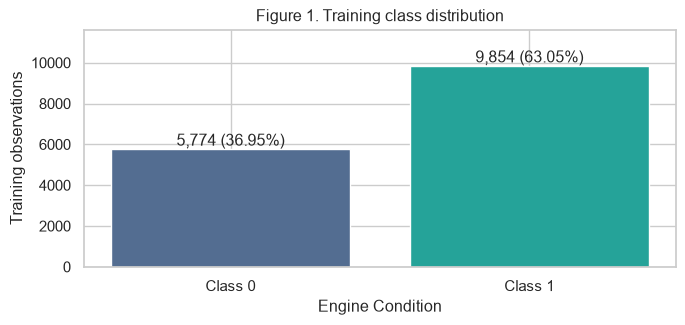

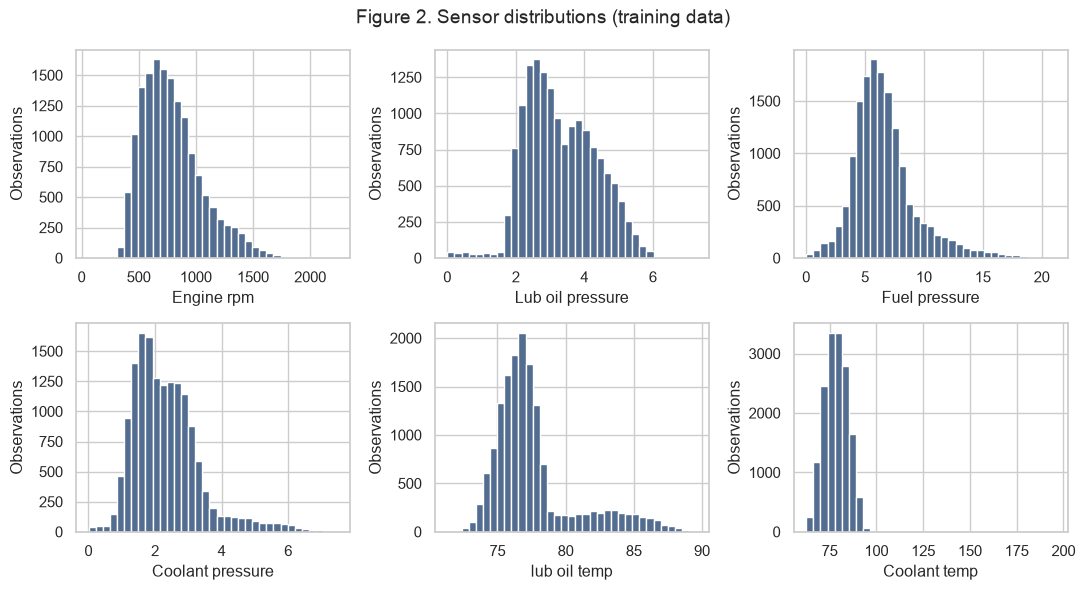

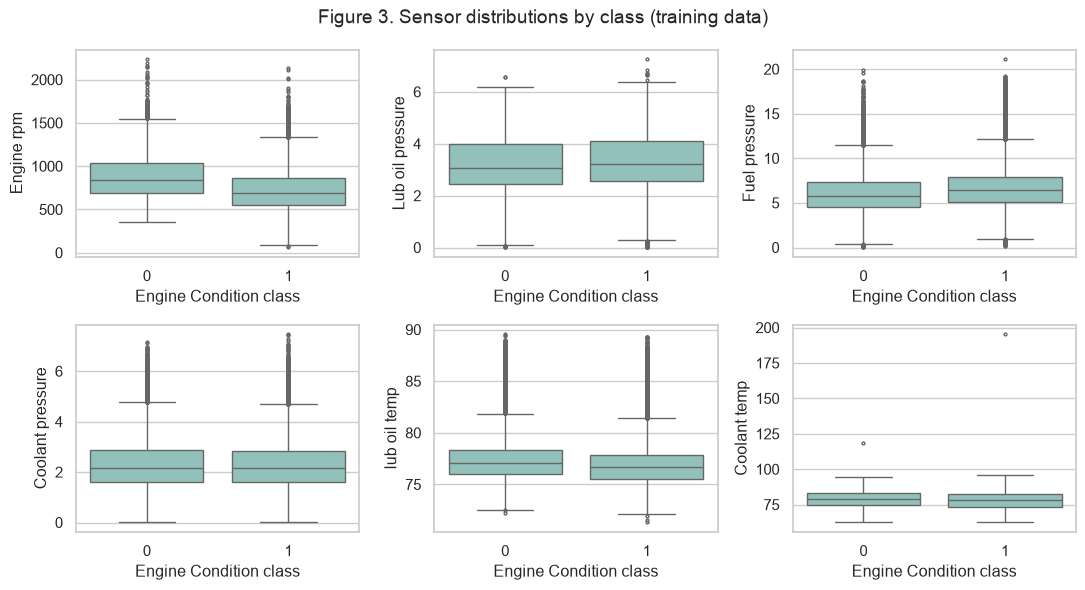

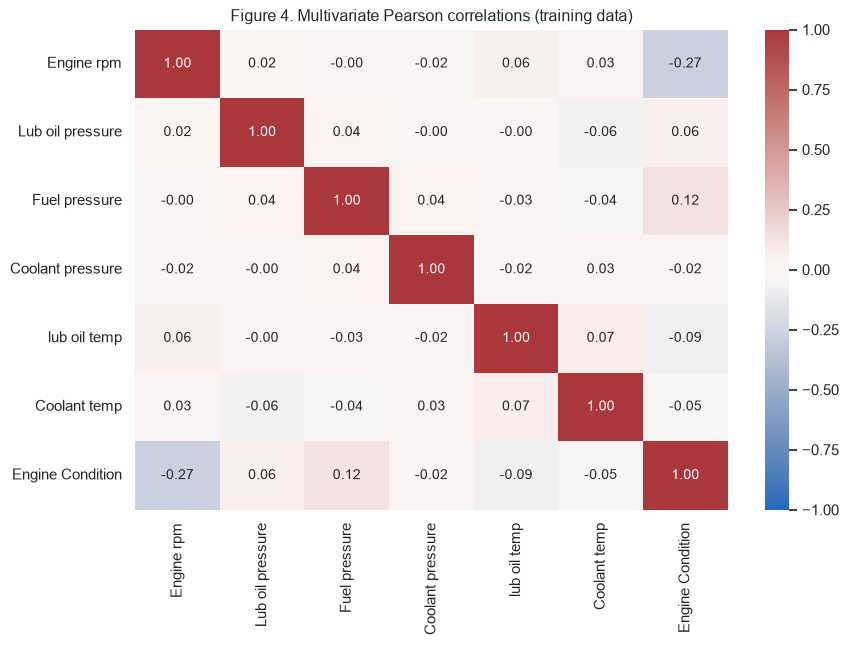

Class 1 represents 63.05% of training observations. A majority-class prediction can therefore appear accurate while never recognizing class 0; balanced accuracy and both-class diagnostics are needed.
Engine rpm averages 885.74 for class 0 and 737.49 for class 1. The distributions overlap, so rpm alone should not be used as a maintenance rule.
Engine rpm has the strongest absolute linear association with the target (r = -0.27). This describes an association with the encoded class, not a cause of engine condition.
The strongest sensor-to-sensor correlation is lub oil temp versus Coolant temp (r = 0.07). Weak pairwise correlations do not rule out nonlinear relationships or interactions.
Coolant temp has a median of 78.34 and a maximum of 195.53; 2 readings lie outside its 1.5-IQR limits. Retain these readings because they may describe unusual operating conditions; verify units and sensor calibration before applying physical limits.
No identifier, timestamp, or failure-mode field is presen

In [3]:
splits = Path('artifacts/final/splits')
train, test = prepare(cfg, splits)
print('Training:', train.shape, 'Test:', test.shape)
"""Training-only exploratory analysis and held-out diagnostic plots."""
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay


def explore(train, cfg, output):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    target = cfg['target']
    features = train.drop(columns=target).columns.tolist()
    sns.set_theme(style='whitegrid', font_scale=0.95)
    summary = train[features].describe().T
    q1, q3 = summary['25%'], summary['75%']
    iqr = q3 - q1
    outlier_counts = ((train[features] < q1 - 1.5*iqr) | (train[features] > q3 + 1.5*iqr)).sum()
    summary['IQR flags'] = outlier_counts
    groups = train.groupby(target)[features].mean().T
    groups.columns = ['Class 0 mean', 'Class 1 mean']
    groups['Difference (1 - 0)'] = groups['Class 1 mean'] - groups['Class 0 mean']
    corr = train.corr()
    summary.to_csv(output / 'feature_summary.csv')
    groups.to_csv(output / 'class_comparison.csv')
    corr.to_csv(output / 'correlations.csv')
    print('Table 1. Training feature overview; pressure/temperature units were not supplied.')
    display(summary.round(2))
    print('Table 2. Training feature means by class (associations, not causal effects).')
    display(groups.round(2))
    print('Table 3. Training missing values and IQR outlier flags (flags are retained).')
    display(pd.DataFrame({'Missing': train[features].isna().sum(), 'IQR flags': outlier_counts}))

    def finish(fig, number):
        fig.tight_layout()
        fig.savefig(output / f'figure_{number}.png', dpi=180, bbox_inches='tight')
        plt.show()
        plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 3.4))
    counts = train[target].value_counts().sort_index()
    ax.bar(['Class 0', 'Class 1'], counts, color=['#536d91', '#25a399'])
    for i, count in enumerate(counts):
        ax.text(i, count, f'{count:,} ({count/len(train):.2%})', ha='center', va='bottom')
    ax.set(ylim=(0, counts.max()*1.18), xlabel='Engine Condition', ylabel='Training observations',
           title='Figure 1. Training class distribution')
    finish(fig, 1)

    fig, axes = plt.subplots(2, 3, figsize=(11, 6))
    for col, ax in zip(features, axes.flat):
        ax.hist(train[col], bins=35, color='#536d91', edgecolor='white')
        ax.set(xlabel=col, ylabel='Observations')
    fig.suptitle('Figure 2. Sensor distributions (training data)', fontsize=14)
    finish(fig, 2)

    fig, axes = plt.subplots(2, 3, figsize=(11, 6))
    for col, ax in zip(features, axes.flat):
        sns.boxplot(data=train, x=target, y=col, ax=ax, color='#8ac9c2', fliersize=2)
        ax.set(xlabel='Engine Condition class', ylabel=col)
    fig.suptitle('Figure 3. Sensor distributions by class (training data)', fontsize=14)
    finish(fig, 3)

    fig, ax = plt.subplots(figsize=(9, 6.6))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1,
                ax=ax, annot_kws={'size':10})
    ax.set_title('Figure 4. Multivariate Pearson correlations (training data)')
    finish(fig, 4)

    target_corr = corr[target].drop(target)
    strongest = target_corr.abs().idxmax()
    upper_triangle = np.triu(np.ones((len(features), len(features)), dtype=bool), k=1)
    feature_corr = corr.loc[features, features].where(upper_triangle).stack()
    pair = feature_corr.abs().idxmax()
    rpm_means = groups.loc['Engine rpm']
    coolant = summary.loc['Coolant temp']
    notes = [
        f'Class 1 represents {100*train[target].mean():.2f}% of training observations. A majority-class prediction can therefore appear accurate while never recognizing class 0; balanced accuracy and both-class diagnostics are needed.',
        f'Engine rpm averages {rpm_means.iloc[0]:.2f} for class 0 and {rpm_means.iloc[1]:.2f} for class 1. The distributions overlap, so rpm alone should not be used as a maintenance rule.',
        f'{strongest} has the strongest absolute linear association with the target (r = {target_corr[strongest]:.2f}). This describes an association with the encoded class, not a cause of engine condition.',
        f'The strongest sensor-to-sensor correlation is {pair[0]} versus {pair[1]} (r = {feature_corr[pair]:.2f}). Weak pairwise correlations do not rule out nonlinear relationships or interactions.',
        f'Coolant temp has a median of {coolant["50%"]:.2f} and a maximum of {coolant["max"]:.2f}; {int(outlier_counts["Coolant temp"])} readings lie outside its 1.5-IQR limits. Retain these readings because they may describe unusual operating conditions; verify units and sensor calibration before applying physical limits.',
        'No identifier, timestamp, or failure-mode field is present. All six sensor features are retained. These measurements support contemporaneous condition classification; the data cannot establish advance warning time or remaining useful life.'
    ]
    (output / 'eda_insights.json').write_text(json.dumps(notes, indent=2))
    for note in notes:
        print(note)
    return notes


def diagnostics(test, cfg, model_dir, output):
    output = Path(output)
    model = joblib.load(Path(model_dir) / 'best_model.joblib')
    metrics = json.loads((Path(model_dir) / 'metrics.json').read_text())
    y = test[cfg['target']]
    X = test.drop(columns=cfg['target'])
    probability = model.predict_proba(X)[:, 1]
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(metrics['random_forest']['confusion_matrix'], annot=True, fmt='d', cmap='Blues',
                xticklabels=['Class 0','Class 1'], yticklabels=['Class 0','Class 1'], ax=ax)
    ax.set(xlabel='Predicted class', ylabel='Actual class', title='Figure 6. Held-out confusion matrix')
    fig.tight_layout(); fig.savefig(output / 'figure_5.png', dpi=180); plt.show(); plt.close(fig)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    RocCurveDisplay.from_predictions(y, probability, ax=axes[0], name='Random forest')
    axes[0].plot([0,1],[0,1], '--', color='grey', label='Chance'); axes[0].legend()
    PrecisionRecallDisplay.from_predictions(y, probability, ax=axes[1], name='Random forest')
    axes[1].axhline(y.mean(), linestyle='--', color='grey', label='Class 1 prevalence'); axes[1].legend()
    fig.suptitle('Figure 5. Held-out ranking performance (positive class = 1)')
    fig.tight_layout(); fig.savefig(output / 'figure_6.png', dpi=180); plt.show(); plt.close(fig)
    print('Table 5. Held-out metrics (positive class = 1).')
    display(pd.DataFrame({name:{k:v for k,v in metrics[name].items() if k!='confusion_matrix'}
                          for name in ['baseline','random_forest']}).round(2))
    print(f"Held-out balanced accuracy: {metrics['random_forest']['balanced_accuracy']:.2f}; "
          f"baseline: {metrics['baseline']['balanced_accuracy']:.2f}. "
          f"Class-1 F1: {metrics['random_forest']['f1']:.2f}; baseline: {metrics['baseline']['f1']:.2f}.")
    print('Selection optimized cross-validated average precision, not F1 at threshold 0.5. '
          'The majority baseline has class-1 recall of 1.00 but recognizes no class-0 observations. '
          'The forest trades some class-1 recall for class-0 recognition; threshold choice needs validation data and operational costs.')

notes = explore(train, cfg, Path('reports/final'))

## 3. Data preparation

### Methodology
Retain all six sensors; no unnecessary columns, missing values or duplicate rows were found. Median imputation is fitted inside each training fold. Save CSV splits and checksum metadata. Hosted preparation uploads these files, and the separate training job downloads and validates them. No timestamps or engine identifiers are available for a time-based or group-based split.

In [4]:
print((splits / 'split_metadata.json').read_text())
print('Saved split files:', sorted(p.name for p in splits.iterdir()))
print('No rows removed; all six sensor features retained.')

{
  "train_rows": 15628,
  "test_rows": 3907,
  "removed_rows": 0,
  "seed": 42,
  "target": "Engine Condition",
  "positive_label": 1,
  "drop_columns": [],
  "source_sha256": "616c7b985ec00e299061f02b11fd866f8eca16b5e8d15d4a61a5fbfd116b8045",
  "split_sha256": {
    "train": "cb2ed6e952ec52c2b14d60165ba8bf9e77537e7f4c29215fe51a8712df659f78",
    "test": "25c2dc140bd54e619db312d40906ca20cfa711027814e435bdfc74a95cd5472f"
  }
}
Saved split files: ['registration.json', 'split_metadata.json', 'test.csv', 'train.csv']
No rows removed; all six sensor features retained.


## 4. Model building with experimentation tracking

### Methodology
Compare 16 random-forest parameter combinations using three-fold stratified cross-validation. Select mean average precision (class 1), refit the best pipeline, and evaluate at the fixed 0.50 threshold. A prior classifier is the baseline. This cell performs a fresh local reproduction; the following section separately verifies the committed hosted model.

In [5]:
local_metrics = train_model(cfg, splits, Path('artifacts/final/model'))
print('Full local tuning log: all parameters, fold scores, training scores, ranks and timings')
with pd.option_context('display.max_columns', None, 'display.max_rows', None):
    display(pd.read_csv('artifacts/final/model/experiments.csv'))
print(Path('artifacts/final/model/run_metadata.json').read_text())

{
  "baseline": {
    "average_precision": 0.6304069618633222,
    "roc_auc": 0.5,
    "balanced_accuracy": 0.5,
    "precision": 0.6304069618633222,
    "recall": 1.0,
    "f1": 0.7733124018838304,
    "confusion_matrix": [
      [
        0,
        1444
      ],
      [
        0,
        2463
      ]
    ]
  },
  "random_forest": {
    "average_precision": 0.7975690662213403,
    "roc_auc": 0.6937947551743646,
    "balanced_accuracy": 0.6469833873741344,
    "precision": 0.7616478666012751,
    "recall": 0.6305318717011774,
    "f1": 0.6899155930697468,
    "confusion_matrix": [
      [
        958,
        486
      ],
      [
        910,
        1553
      ]
    ]
  },
  "best_cv_average_precision": 0.7938184156247289,
  "best_parameters": {
    "model__class_weight": "balanced",
    "model__max_depth": 10,
    "model__min_samples_leaf": 1,
    "model__n_estimators": 100
  },
  "test_prevalence": 0.6304069618633222,
  "decision_threshold": 0.5
}
Full local tuning log: all parame

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__class_weight,param_model__max_depth,param_model__min_samples_leaf,param_model__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,mean_train_score,std_train_score
0,0.987023,0.006386,0.051407,0.000171,NaN,NaN,1,100,"{'model__class_weight': None, 'model__max_dept...",0.773565,0.763755,0.775669,0.770996,0.005192,16,1.000000,1.000000,1.000000,1.000000,9.064933e-17
1,1.965897,0.029325,0.101861,0.000123,NaN,NaN,1,200,"{'model__class_weight': None, 'model__max_dept...",0.777524,0.767024,0.778131,0.774226,0.005099,14,1.000000,1.000000,1.000000,1.000000,0.000000e+00
2,0.929120,0.013466,0.045624,0.000160,NaN,NaN,3,100,"{'model__class_weight': None, 'model__max_dept...",0.783303,0.775010,0.784577,0.780963,0.004242,12,0.998629,0.998756,0.998876,0.998753,1.006587e-04
3,1.835801,0.007865,0.089876,0.001595,NaN,NaN,3,200,"{'model__class_weight': None, 'model__max_dept...",0.786407,0.774732,0.788035,0.783058,0.005925,9,0.998982,0.998972,0.999127,0.999027,7.095731e-05
4,0.709332,0.004895,0.029414,0.000208,NaN,10.0,1,100,"{'model__class_weight': None, 'model__max_dept...",0.794751,0.785108,0.797783,0.792547,0.005404,5,0.927782,0.930175,0.927004,0.928320,1.349463e-03
5,1.428060,0.003706,0.056406,0.000245,NaN,10.0,1,200,"{'model__class_weight': None, 'model__max_dept...",0.793977,0.785224,0.798351,0.792517,0.005458,6,0.928166,0.931071,0.928599,0.929278,1.279985e-03
6,0.714601,0.001230,0.029225,0.000418,NaN,10.0,3,100,"{'model__class_weight': None, 'model__max_dept...",0.792666,0.784981,0.797028,0.791558,0.004980,8,0.915419,0.920779,0.915238,0.917146,2.570594e-03
7,1.413838,0.005460,0.056085,0.000420,NaN,10.0,3,200,"{'model__class_weight': None, 'model__max_dept...",0.794592,0.785793,0.798164,0.792850,0.005198,4,0.916384,0.920318,0.916319,0.917674,1.869828e-03
8,1.029690,0.005394,0.051565,0.000130,balanced,NaN,1,100,"{'model__class_weight': 'balanced', 'model__ma...",0.777870,0.768498,0.776075,0.774147,0.004061,15,1.000000,1.000000,1.000000,1.000000,6.409876e-17
9,2.068249,0.014135,0.100691,0.001121,balanced,NaN,1,200,"{'model__class_weight': 'balanced', 'model__ma...",0.780867,0.770866,0.780167,0.777300,0.004559,13,1.000000,1.000000,1.000000,1.000000,9.064933e-17


{
  "configuration": {
    "dataset": "data/engine_data.csv",
    "source": "Parv Modi, Automotive Vehicles Engine Health Dataset, Kaggle, version 1 (2023). The user-supplied engine_data.csv was verified byte-for-byte against the public download on 2 November 2026. Collection protocol and pressure/temperature units remain unverified.",
    "learner_name": "Harshit Rathi",
    "target": "Engine Condition",
    "positive_label": 1,
    "expected_columns": [
      "Engine rpm",
      "Lub oil pressure",
      "Fuel pressure",
      "Coolant pressure",
      "lub oil temp",
      "Coolant temp",
      "Engine Condition"
    ],
    "numeric_columns": [
      "Engine rpm",
      "Lub oil pressure",
      "Fuel pressure",
      "Coolant pressure",
      "lub oil temp",
      "Coolant temp"
    ],
    "drop_columns": [],
    "label_note": "The healthy/faulty mapping remains unverified because external sources conflict. This report retains class 0/class 1 terminology throughout. Class 1 is the 

### Evaluation of the committed deployment model

The final report uses the model saved by GitHub Actions in `models/`, which is also loaded by Streamlit. Recompute its metrics on the same held-out split and check them against the hosted record. Show the complete hosted tuning log as well. Small platform-dependent differences between local and hosted random forests are documented rather than mixing the two sets of results.

Committed-model metrics match the hosted record; split checksums match.


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_model__class_weight,param_model__max_depth,param_model__min_samples_leaf,param_model__n_estimators,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,mean_train_score,std_train_score
0,4.489220,0.049743,0.236222,0.012927,NaN,NaN,1,100,"{'model__class_weight': None, 'model__max_dept...",0.773792,0.764323,0.774606,0.770907,0.004667,16,1.000000,1.000000,1.000000,1.000000,1.433292e-16
1,9.078959,0.283364,0.354640,0.032945,NaN,NaN,1,200,"{'model__class_weight': None, 'model__max_dept...",0.778124,0.767276,0.777496,0.774299,0.004972,14,1.000000,1.000000,1.000000,1.000000,0.000000e+00
2,3.929237,0.213320,0.201962,0.023502,NaN,NaN,3,100,"{'model__class_weight': None, 'model__max_dept...",0.782702,0.774400,0.784911,0.780671,0.004525,12,0.998621,0.998765,0.998887,0.998758,1.086019e-04
3,8.233131,0.049936,0.377813,0.018160,NaN,NaN,3,200,"{'model__class_weight': None, 'model__max_dept...",0.786109,0.774392,0.787499,0.782667,0.005879,10,0.998987,0.998984,0.999128,0.999033,6.702655e-05
4,3.266668,0.054725,0.126502,0.006291,NaN,10.0,1,100,"{'model__class_weight': None, 'model__max_dept...",0.794779,0.785126,0.797801,0.792569,0.005405,5,0.927749,0.930148,0.927006,0.928301,1.340887e-03
5,6.333927,0.174843,0.203969,0.052683,NaN,10.0,1,200,"{'model__class_weight': None, 'model__max_dept...",0.793905,0.785182,0.798365,0.792484,0.005475,6,0.928191,0.931049,0.928600,0.929280,1.261959e-03
6,3.151515,0.063621,0.113269,0.040909,NaN,10.0,3,100,"{'model__class_weight': None, 'model__max_dept...",0.792362,0.785032,0.797153,0.791516,0.004984,8,0.915860,0.920747,0.915206,0.917271,2.472331e-03
7,6.128332,0.294918,0.245816,0.028455,NaN,10.0,3,200,"{'model__class_weight': None, 'model__max_dept...",0.794287,0.785793,0.798182,0.792754,0.005173,4,0.916736,0.920312,0.916293,0.917781,1.799082e-03
8,4.512521,0.081543,0.206997,0.000510,balanced,NaN,1,100,"{'model__class_weight': 'balanced', 'model__ma...",0.776882,0.767732,0.776618,0.773744,0.004252,15,1.000000,1.000000,1.000000,1.000000,1.433292e-16
9,9.323606,0.157596,0.372848,0.049011,balanced,NaN,1,200,"{'model__class_weight': 'balanced', 'model__ma...",0.780496,0.770417,0.780402,0.777105,0.004729,13,1.000000,1.000000,1.000000,1.000000,9.064933e-17


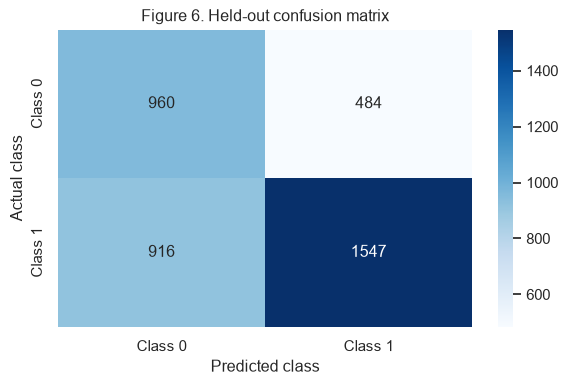

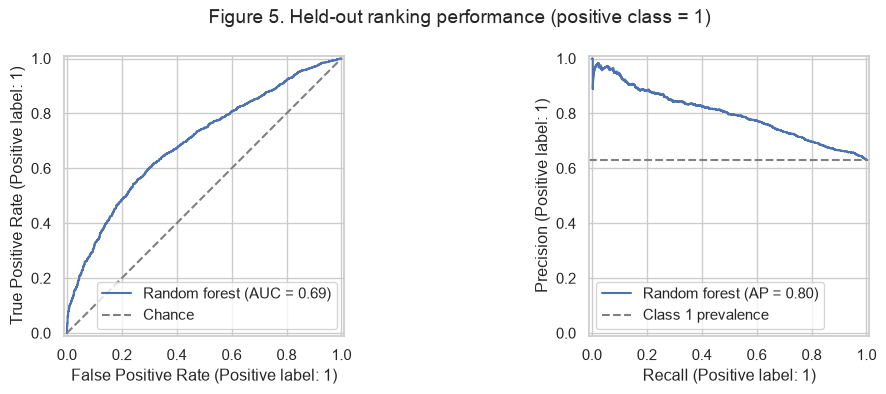

Table 5. Held-out metrics (positive class = 1).


,baseline,random_forest
average_precision,0.63,0.80
roc_auc,0.50,0.69
balanced_accuracy,0.50,0.65
precision,0.63,0.76
recall,1.00,0.63
f1,0.77,0.69


Held-out balanced accuracy: 0.65; baseline: 0.50. Class-1 F1: 0.69; baseline: 0.77.
Selection optimized cross-validated average precision, not F1 at threshold 0.5. The majority baseline has class-1 recall of 1.00 but recognizes no class-0 observations. The forest trades some class-1 recall for class-0 recognition; threshold choice needs validation data and operational costs.
Local versus hosted model metrics (full precision):


,Local reproduction,Committed hosted model
average_precision,0.797569,0.797655
roc_auc,0.693795,0.694027
balanced_accuracy,0.646983,0.646458
precision,0.761648,0.761694
recall,0.630532,0.628096
f1,0.689916,0.688474


Full hosted parameters:
{
  "memory": null,
  "steps": [
    [
      "preprocessing",
      "ColumnTransformer(transformers=[('numeric', SimpleImputer(strategy='median'),\n                                 ['Engine rpm', 'Lub oil pressure',\n                                  'Fuel pressure', 'Coolant pressure',\n                                  'lub oil temp', 'Coolant temp']),\n                                ('categorical',\n                                 Pipeline(steps=[('impute',\n                                                  SimpleImputer(strategy='most_frequent')),\n                                                 ('encode',\n                                                  OneHotEncoder(handle_unknown='ignore'))]),\n                                 [])])"
    ],
    [
      "model",
      "RandomForestClassifier(class_weight='balanced', max_depth=10, n_jobs=1,\n                       random_state=42)"
    ]
  ],
  "transform_input": null,
  "verbose": false,
  "preprocess

In [6]:
hosted = json.loads(Path('models/metrics.json').read_text())
hosted_run = json.loads(Path('models/run_metadata.json').read_text())
for name, digest in hosted_run['splits']['split_sha256'].items():
    assert hashlib.sha256((splits / f'{name}.csv').read_bytes()).hexdigest() == digest
committed_model = joblib.load('models/best_model.joblib')
verified = evaluate(committed_model, test.drop(columns=cfg['target']), test[cfg['target']])
for key, value in verified.items():
    np.testing.assert_allclose(value, hosted['random_forest'][key], rtol=0, atol=1e-12)
print('Committed-model metrics match the hosted record; split checksums match.')
with pd.option_context('display.max_columns', None, 'display.max_rows', None):
    display(pd.read_csv('models/experiments.csv'))
diagnostics(test, cfg, Path('models'), Path('reports/final'))
comparison = pd.DataFrame({'Local reproduction': local_metrics['random_forest'], 'Committed hosted model': hosted['random_forest']}).drop(index='confusion_matrix')
print('Local versus hosted model metrics (full precision):')
display(comparison)
print('Full hosted parameters:')
print(Path('models/best_parameters.json').read_text())
print('Hosted lineage and environment:')
print(Path('models/run_metadata.json').read_text())

## 5. Model deployment

### Methodology
Load the committed model and its feature profile. Collect six numeric inputs into a dataframe in the training column order, validate finite numbers, and return the original dataset class and class-1 score. Defaults are rounded training medians. The app warns about inputs outside the observed training range. It does not relabel the target or claim a calibrated failure probability.

In [7]:
"""Load the repository model and validate a single engine observation."""
import hashlib
import json
from importlib.metadata import version
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

ROOT = Path.cwd()


def load_bundle(model_dir=None):
    directory = Path(model_dir) if model_dir is not None else ROOT / 'models'
    metadata = json.loads((directory / 'run_metadata.json').read_text())
    profile = json.loads((directory / 'input_profile.json').read_text())
    model_path = directory / 'best_model.joblib'
    if hashlib.sha256(model_path.read_bytes()).hexdigest() != profile['model_sha256']:
        raise ValueError('Model and input profile do not match. Refresh the model bundle.')
    for package in ['scikit-learn', 'numpy', 'pandas', 'joblib']:
        if version(package) != metadata['packages'][package]:
            raise ValueError(f'{package} differs from the training environment. Install requirements.txt.')
    # Only the trusted model committed by this project is loaded, never user uploads.
    model = joblib.load(model_path)
    if list(model.feature_names_in_) != profile['features']:
        raise ValueError('Model feature order does not match the input profile.')
    return model, profile, metadata


def predict_observation(values, model, profile):
    features = profile['features']
    if set(values) != set(features):
        raise ValueError('Provide exactly the six required sensor readings.')
    frame = pd.DataFrame([values], columns=features).astype(float)
    if not np.isfinite(frame.to_numpy()).all():
        raise ValueError('Every sensor reading must be a finite number.')
    outside = [name for name in features
               if not profile['summary'][name]['minimum'] <= frame.iloc[0][name]
               <= profile['summary'][name]['maximum']]
    prediction = int(model.predict(frame)[0])
    positive_index = list(model.classes_).index(1)
    score = float(model.predict_proba(frame)[0, positive_index])
    return frame, prediction, score, outside

model, profile, metadata = load_bundle()
values = {name: round(profile['summary'][name]['median'], 2) for name in profile['features']}
frame, predicted, score, outside = predict_observation(values, model, profile)
display(frame)
print({'predicted_class': predicted, 'class_1_score': score, 'outside_training_range': outside})
print('Model SHA-256:', profile['model_sha256'])
Path('reports/final/sample_prediction.json').write_text(json.dumps({'inputs': values, 'class': predicted, 'score': score}, indent=2))

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp
0,748.0,3.16,6.19,2.17,76.82,78.34


{'predicted_class': 1, 'class_1_score': 0.5718843149277737, 'outside_training_range': []}
Model SHA-256: 00927ad943f5eec6ab496ab0c83614c1425c579dff1853f7430732dbdd076068


231

In [8]:
from IPython.display import Markdown
print('Complete Streamlit app source (the deployed entry point):')
display(Markdown('```python\n' + Path('streamlit_app.py').read_text() + '\n```'))
print('Deployment dependencies:')
print(Path('requirements.txt').read_text())
print('Streamlit theme configuration:')
print(Path('.streamlit/config.toml').read_text())

Complete Streamlit app source (the deployed entry point):


```python
"""Streamlit Community Cloud entry point for the committed engine model."""
import streamlit as st

from src.inference import load_bundle, predict_observation

st.set_page_config(page_title='Engine Condition | Predictive Maintenance', page_icon='⚙️', layout='wide')
st.caption('HARSHIT RATHI · AIML CAPSTONE PROJECT 3')
st.title('Engine condition assessment')
st.write('Enter six sensor readings to classify an engine observation with the trained random forest.')
st.info('Class 0 and class 1 are dataset labels. Their healthy/faulty meanings are unverified. '
        'This demonstration does not predict time to failure or issue maintenance orders.')


@st.cache_resource
def get_model():
    return load_bundle()


try:
    model, profile, metadata = get_model()
except (OSError, ValueError, KeyError) as exc:
    st.error(f'The model could not be loaded: {exc}')
    st.stop()

with st.form('sensor_readings'):
    st.subheader('Sensor readings')
    st.caption('Defaults are training-set medians. Use the dataset’s measurement scale; '
               'pressure and temperature units were not documented.')
    columns = st.columns(3)
    values = {}
    for i, name in enumerate(profile['features']):
        limits = profile['summary'][name]
        with columns[i % 3]:
            values[name] = st.number_input(
                name, value=round(limits['median'], 2), step=1.0 if name == 'Engine rpm' else 0.1,
                format='%.2f', key=name,
                help=f"Observed training range: {limits['minimum']:.2f} to {limits['maximum']:.2f}. "
                     'These are sample ranges, not verified physical limits.')
    submitted = st.form_submit_button('Assess condition', type='primary')

if submitted:
    try:
        frame, prediction, score, outside = predict_observation(values, model, profile)
    except (ValueError, TypeError) as exc:
        st.error(str(exc))
    else:
        st.subheader('Assessment result')
        left, right = st.columns(2)
        left.metric('Predicted dataset class', f'Class {prediction}')
        right.metric('Class 1 model score', f'{score:.2%}')
        st.caption('The score is an uncalibrated model probability for class 1, not a probability of engine failure. '
                   'The model uses a fixed decision threshold of 0.50; an exact tie is assigned to class 0.')
        if outside:
            st.warning('Outside the observed training range: ' + ', '.join(outside) +
                       '. Treat this result cautiously and verify the readings.')
        st.write('Readings used for this assessment')
        st.dataframe(frame, hide_index=True, width='stretch')
        st.download_button('Download assessment CSV',
                           frame.assign(predicted_class=prediction, class_1_score=score).to_csv(index=False),
                           file_name='engine_condition_assessment.csv', mime='text/csv')

with st.expander('About this model'):
    st.write('Trained on six numeric sensors with a stratified 80/20 split and three-fold cross-validation. '
             'The deployed model is loaded from the GitHub repository; it is not retrained when you enter readings.')
    st.write('Before operational use, confirm label meanings and units, validate on new engines and later periods, '
             'and choose an inspection policy using validation data and agreed error costs.')
    st.link_button('View project on GitHub', 'https://github.com/harshitrathi14/capstone-predictivemaintenance')
st.caption('Inputs are processed for this session and are not written to a server-side prediction log.')

```

Deployment dependencies:
pandas==2.3.3
numpy==2.5.4
scikit-learn==1.9.1
matplotlib>=3.9,<4
seaborn>=0.13,<1
joblib==1.6.0
streamlit==1.67.0
nbformat>=5.10,<6
nbconvert>=7.16,<8
ipykernel>=6.29,<8
reportlab>=4.2,<5

Streamlit theme configuration:
[theme]
primaryColor = "#176d70"
backgroundColor = "#ffffff"
secondaryBackgroundColor = "#edf4f5"
textColor = "#17354d"
font = "sans serif"

[browser]
gatherUsageStats = false



## 6. Automated GitHub Actions workflow

### Methodology
The prepare job validates the dataset and uploads splits. The train job downloads splits, tunes/evaluates the model, tests the app with the new model and uploads the model bundle. The persist-model job commits the bundle to main. Relevant source changes and manual dispatch trigger the workflow; model-only commits do not retrigger training.

In [9]:
print('Complete workflow YAML:')
print(Path('.github/workflows/pipeline.yml').read_text())
print('Recorded hosted execution:')
print(Path('models/workflow_run.json').read_text())

Complete workflow YAML:
name: Predictive maintenance
on:
  workflow_dispatch:
  push:
    branches: [main]
    paths:
      - 'data/**'
      - 'src/pipeline.py'
      - 'src/inference.py'
      - 'streamlit_app.py'
      - '.streamlit/**'
      - 'tests/**'
      - 'config.json'
      - 'requirements.txt'
      - '.github/workflows/pipeline.yml'
permissions:
  contents: read
concurrency:
  group: predictive-maintenance-${{ github.ref }}
  cancel-in-progress: true
jobs:
  prepare:
    runs-on: ubuntu-latest
    timeout-minutes: 15
    steps:
      - uses: actions/checkout@v4
      - uses: actions/setup-python@v5
        with:
          python-version: '3.12'
          cache: pip
      - name: Install dependencies
        run: pip install -r requirements.txt
      - name: Verify pipeline behavior
        run: python -m unittest discover -s tests -p 'test_pipeline.py' -v
      - name: Validate data and save train/test splits
        run: python src/pipeline.py prepare
      - uses: actio

## 7. Output evaluation

### Methodology
Check the actual repository and successful hosted workflow, then submit the same default sensor values to the public Streamlit app and compare its displayed prediction with the committed model. Screenshots are browser captures of the real pages, not reconstructed interfaces. The capture record below contains URLs, timestamps and the tested model checksum.

{
  "captured_at": "2026-11-10T11:11:36.332326+05:30",
  "repository_url": "https://github.com/harshitrathi14/capstone-predictivemaintenance",
  "workflow": {
    "id": 42762171518,
    "url": "https://github.com/harshitrathi14/capstone-predictivemaintenance/actions/runs/42762171518",
    "conclusion": "success",
    "head_sha": "0a024f274d62f88852e09d30efa172c1b97d42fa",
    "created_at": "2026-11-10T05:26:44Z",
    "updated_at": "2026-11-10T05:30:22Z",
    "jobs": [
      {
        "name": "prepare",
        "conclusion": "success",
        "url": "https://github.com/harshitrathi14/capstone-predictivemaintenance/actions/runs/42762171518/job/129650191824"
      },
      {
        "name": "train",
        "conclusion": "success",
        "url": "https://github.com/harshitrathi14/capstone-predictivemaintenance/actions/runs/42762171518/job/129650597799"
      },
      {
        "name": "persist-model",
        "conclusion": "success",
        "url": "https://github.com/harshitrathi14/cap

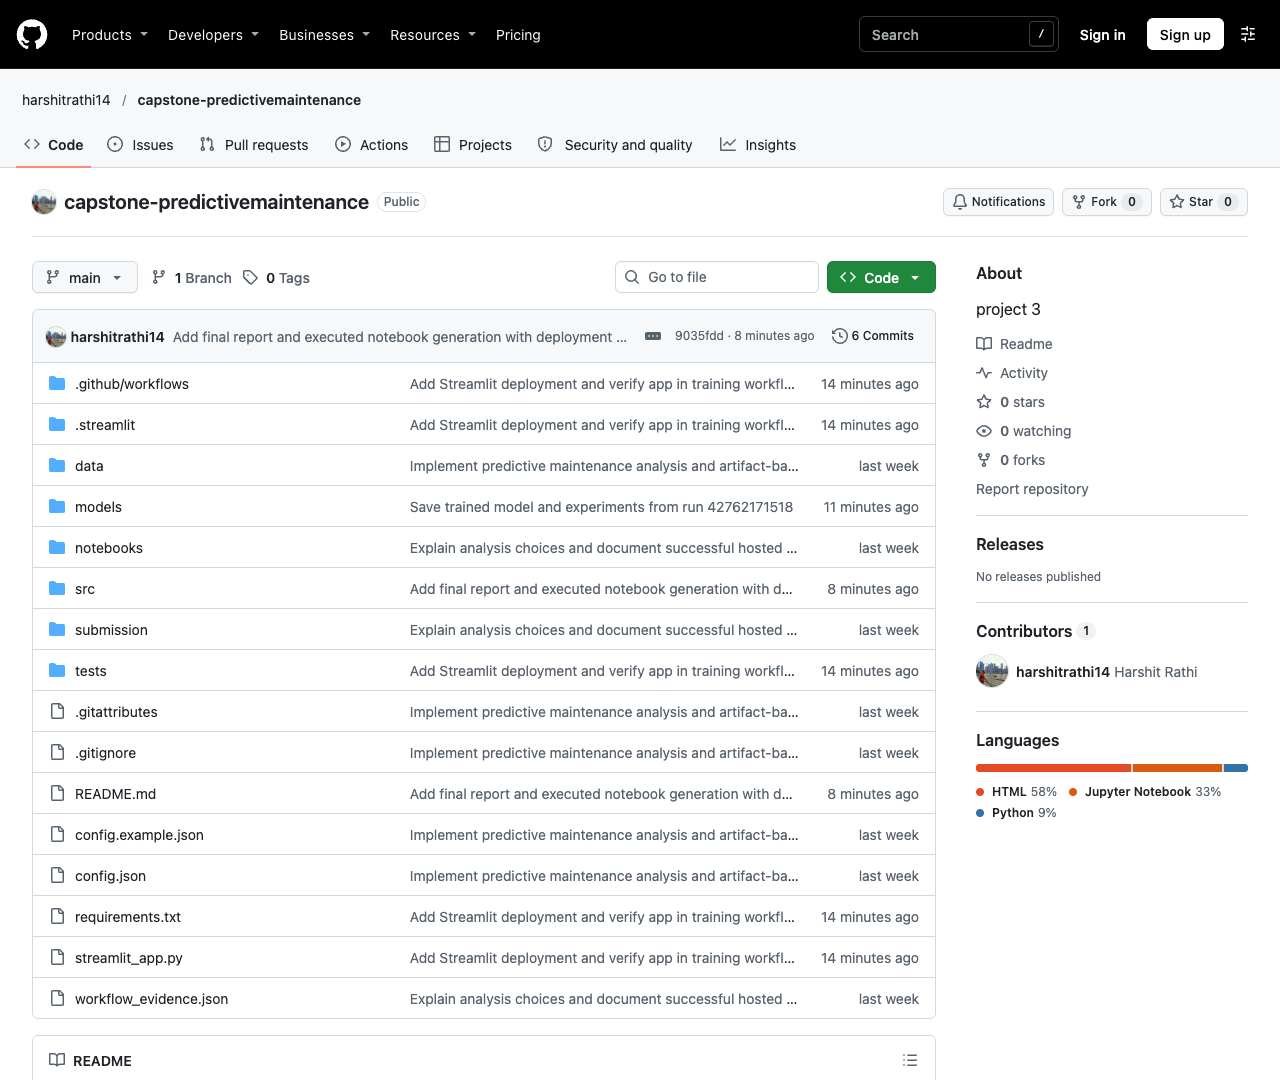

Executed GitHub Actions workflow


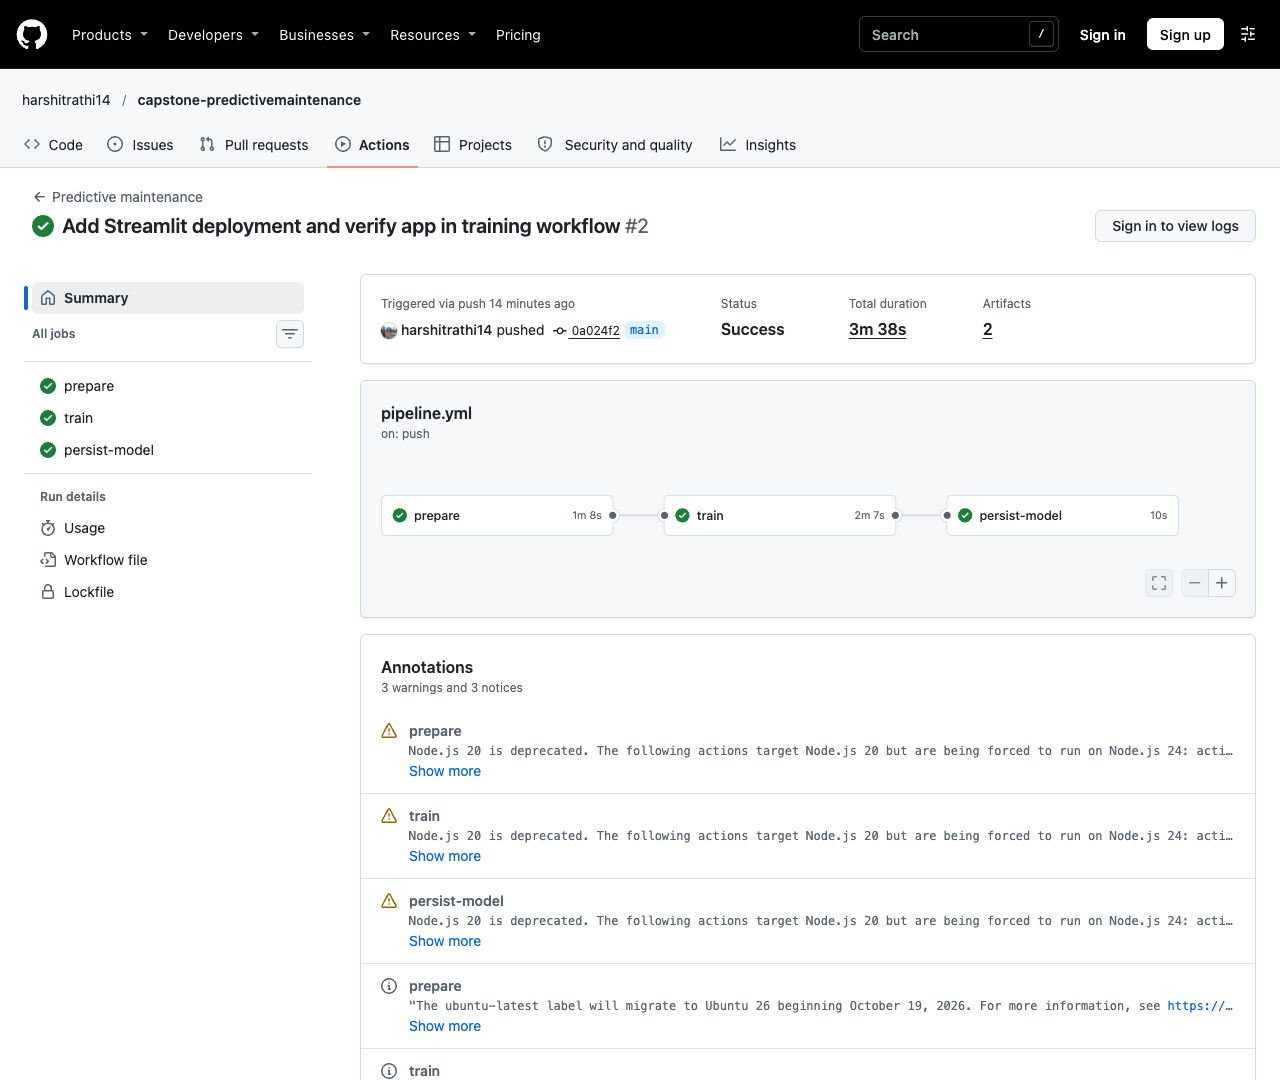

Public Streamlit app prediction


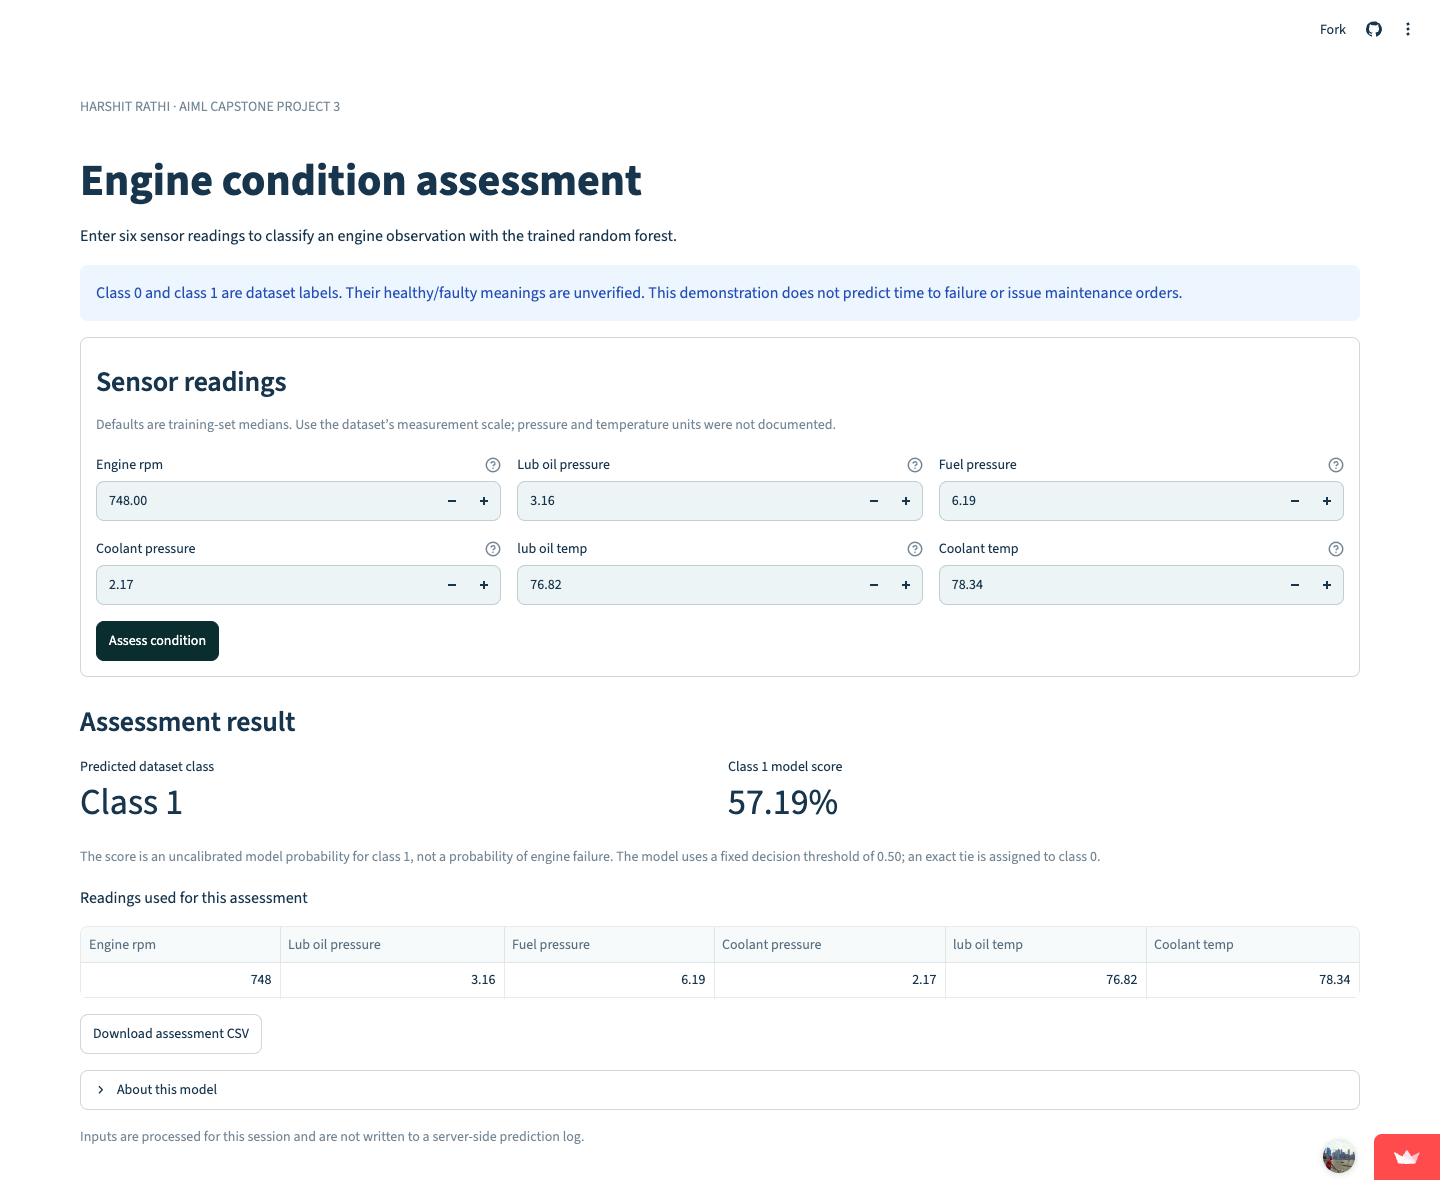

Verification checks:
test_app_submits_and_warns_on_outside_range (test_app.AppTests.test_app_submits_and_warns_on_outside_range) ... 2026-11-10 10:55:56.107 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
ok
test_incomplete_and_nonfinite_readings_rejected (test_app.AppTests.test_incomplete_and_nonfinite_readings_rejected) ... ok
test_saved_model_prediction_matches_form_dataframe (test_app.AppTests.test_saved_model_prediction_matches_form_dataframe) ... ok
test_modified_split_rejected (test_pipeline.PipelineTests.test_modified_split_rejected) ... ok
test_schema_rejected (test_pipeline.PipelineTests.test_schema_rejected) ... ok
test_split_is_disjoint_and_training_roundtrips (test_pipeline.PipelineTests.test_split_is_disjoint_and_training_roundtrips) ... {
  "rows": 90,
  "columns": [
    "id",
    "sensor",
    "type",
    "failure"
  ],
  "missing": {
    "id": 0,
    "

In [10]:
from IPython.display import Image as NotebookImage
captured = json.loads(Path('evidence/final_evidence.json').read_text())
print(json.dumps(captured, indent=2))
for name, label in [('github_repository.png', 'Repository folder structure'), ('github_workflow.png', 'Executed GitHub Actions workflow'), ('streamlit_cloud.png', 'Public Streamlit app prediction')]:
    print(label)
    display(NotebookImage(filename=str(Path('evidence') / name)))
print('Verification checks:')
print(Path('evidence/test_results.txt').read_text())

## 8. Actionable insights and recommendations

The forest improves class separation over the prior baseline but has moderate discrimination and substantial errors. Its class-1 F1 at the default threshold is lower than the majority baseline; the baseline finds no class-0 observations. A business decision must therefore consider both error types.

1. Confirm target meanings, pressure/temperature units and measurement context with the dataset owner.
2. Validate unusual sensor readings rather than discarding them automatically.
3. Obtain engine identifiers, timestamps and later outcomes; evaluate on new engines and later periods.
4. After label confirmation, select an inspection threshold on validation data using agreed error costs.
5. Run an analyst-reviewed pilot, monitor data quality and performance, and retain versioned model artifacts.

The deployment demonstrates repeatable inference and automation. It does not establish production safety, advance warning time, remaining useful life or financial savings.

### Implementation references
- [Streamlit Community Cloud deployment](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy)
- [scikit-learn model persistence](https://scikit-learn.org/stable/model_persistence.html)
- [GitHub workflow artifacts](https://docs.github.com/en/actions/tutorials/store-and-share-data)